# Clasificación de prendas con Fashion-MNIST

Entrena tres arquitecturas CNN, las compara con métricas de clasificación y guarda la mejor para la aplicación de cámara. Se usan los CSV locales del dataset [Fashion-MNIST](https://www.kaggle.com/datasets/zalando-research/fashionmnist).

Ejecuta las celdas en orden. La selección se realiza por accuracy de validación; las métricas de prueba se reportan para las tres redes.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

SEED = 42
EPOCHS = 5
BATCH_SIZE = 128
tf.keras.utils.set_random_seed(SEED)

PROJECT_DIR = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if path.name == 'parcial3' and (path / 'fashion-mnist_train.csv').is_file()),
    Path.cwd() / 'parcial3'
)
DATA_DIR = PROJECT_DIR
CLASS_NAMES = ['Camiseta', 'Pantalón', 'Suéter', 'Vestido', 'Abrigo', 'Sandalia', 'Camisa', 'Tenis', 'Bolso', 'Botín']
print(f'Datos: {DATA_DIR}')
print(f'TensorFlow: {tf.__version__}')

Datos: c:\Users\Camus\OneDrive\Documentos\Projects\ai-projects\parcial3
TensorFlow: 2.21.0


## 1. Carga y preparación

In [2]:
train_df = pd.read_csv(DATA_DIR / 'fashion-mnist_train.csv')
test_df = pd.read_csv(DATA_DIR / 'fashion-mnist_test.csv')

y = train_df.iloc[:, 0].to_numpy(dtype=np.int64)
X = train_df.iloc[:, 1:].to_numpy(dtype=np.float32).reshape(-1, 28, 28, 1) / 255.0
y_test = test_df.iloc[:, 0].to_numpy(dtype=np.int64)
X_test = test_df.iloc[:, 1:].to_numpy(dtype=np.float32).reshape(-1, 28, 28, 1) / 255.0
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.1, random_state=SEED, stratify=y
)
print(f'Entrenamiento: {X_train.shape}; validación: {X_val.shape}; prueba: {X_test.shape}')

Entrenamiento: (54000, 28, 28, 1); validación: (6000, 28, 28, 1); prueba: (10000, 28, 28, 1)


## 2. Tres arquitecturas CNN

In [3]:
def build_simple_cnn():
    return tf.keras.Sequential([
        tf.keras.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(32, 3, activation='relu', padding='same'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(64, 3, activation='relu', padding='same'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(10, activation='softmax'),
    ], name='CNN_simple')

def build_deep_cnn():
    return tf.keras.Sequential([
        tf.keras.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(32, 3, padding='same', use_bias=False),
        tf.keras.layers.BatchNormalization(), tf.keras.layers.Activation('relu'),
        tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
        tf.keras.layers.MaxPooling2D(), tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Conv2D(64, 3, padding='same', use_bias=False),
        tf.keras.layers.BatchNormalization(), tf.keras.layers.Activation('relu'),
        tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
        tf.keras.layers.MaxPooling2D(), tf.keras.layers.Dropout(0.3),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(10, activation='softmax'),
    ], name='CNN_profunda')

def build_separable_cnn():
    return tf.keras.Sequential([
        tf.keras.Input(shape=(28, 28, 1)),
        tf.keras.layers.SeparableConv2D(32, 3, padding='same', activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.SeparableConv2D(64, 3, padding='same', activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.SeparableConv2D(128, 3, padding='same', activation='relu'),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(10, activation='softmax'),
    ], name='CNN_separable')

builders = [build_simple_cnn, build_deep_cnn, build_separable_cnn]
models = {}
histories = {}
validation_accuracy = {}

for build_model in builders:
    model = build_model()
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    history = model.fit(
        X_train, y_train, validation_data=(X_val, y_val),
        epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=1,
        callbacks=[tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', patience=2, restore_best_weights=True
        )],
    )
    models[model.name] = model
    histories[model.name] = history
    validation_accuracy[model.name] = max(history.history['val_accuracy'])
    print(f"{model.name}: mejor accuracy de validación = {validation_accuracy[model.name]:.4f}")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.8046 - loss: 0.5420 - val_accuracy: 0.8725 - val_loss: 0.3522
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.8793 - loss: 0.3383 - val_accuracy: 0.8877 - val_loss: 0.3016
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.8956 - loss: 0.2902 - val_accuracy: 0.8980 - val_loss: 0.2776
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.9070 - loss: 0.2613 - val_accuracy: 0.9072 - val_loss: 0.2600
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9138 - loss: 0.2353 - val_accuracy: 0.9117 - val_loss: 0.2449
CNN_simple: mejor accuracy de validación = 0.9117
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 64ms/step - accuracy: 0.7374 - loss: 0.7486 - val_accuracy: 0.2097 - val_loss: 3.0921
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 27s 64ms/step - accuracy: 0.8403 - loss: 0.4456 - val_accuracy: 0.8373 - val_loss: 0.4296
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 27s 64ms/step

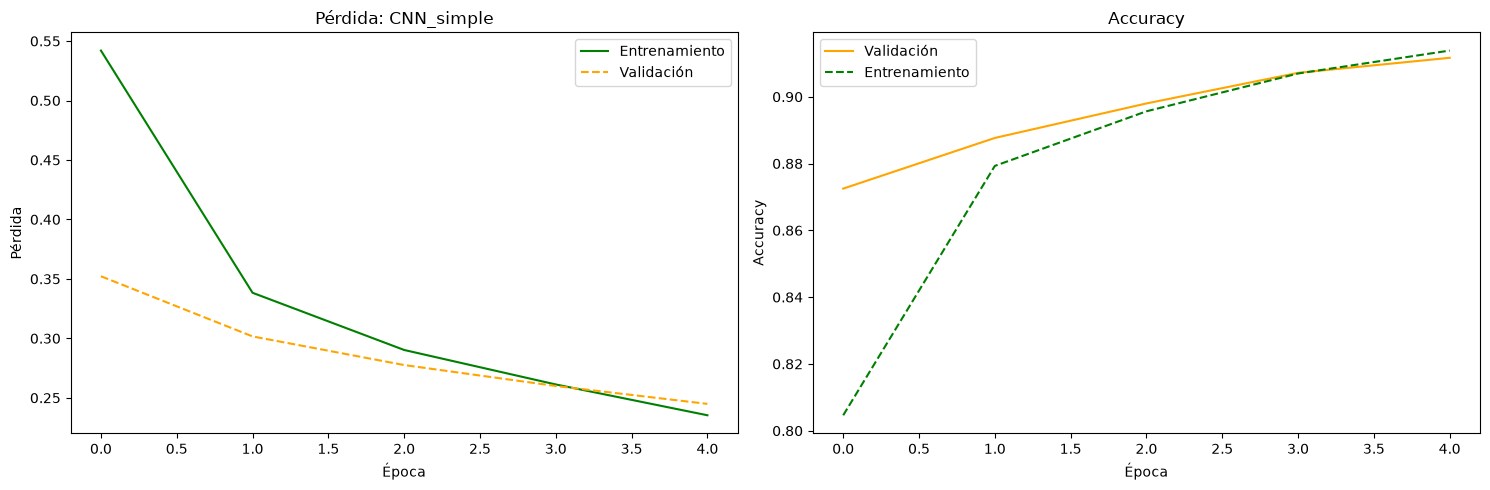

In [9]:
best_for_plot = max(validation_accuracy, key=validation_accuracy.get)
history_to_plot = histories[best_for_plot].history

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(history_to_plot['loss'], color='green', linestyle='-')
axes[0].plot(history_to_plot['val_loss'], color='orange', linestyle='--')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Pérdida')
axes[0].set_title(f'Pérdida: {best_for_plot}')
axes[0].legend(['Entrenamiento', 'Validación'])

axes[1].plot(history_to_plot['val_accuracy'], color='orange', linestyle='-')
axes[1].plot(history_to_plot['accuracy'], color='green', linestyle='--')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy')
axes[1].legend(['Validación', 'Entrenamiento'])

plt.tight_layout()
plt.show()

## 3. Comparación en el conjunto de prueba

In [10]:
rows = []
for name, model in models.items():
    predictions = np.argmax(model.predict(X_test, verbose=0), axis=1)
    rows.append({
        'Modelo': name,
        'Accuracy validación': validation_accuracy[name],
        'Accuracy prueba': accuracy_score(y_test, predictions),
        'Precision macro': precision_score(y_test, predictions, average='macro', zero_division=0),
        'Recall macro': recall_score(y_test, predictions, average='macro', zero_division=0),
        'F1 macro': f1_score(y_test, predictions, average='macro', zero_division=0),
    })

results = pd.DataFrame(rows).sort_values('Accuracy validación', ascending=False).reset_index(drop=True)
display(results.round(4))

,Modelo,Accuracy validación,Accuracy prueba,Precision macro,Recall macro,F1 macro
0,CNN_simple,0.9117,0.9122,0.9158,0.9122,0.9131
1,CNN_profunda,0.8812,0.8833,0.8897,0.8833,0.8840
2,CNN_separable,0.7502,0.7511,0.7470,0.7511,0.7434


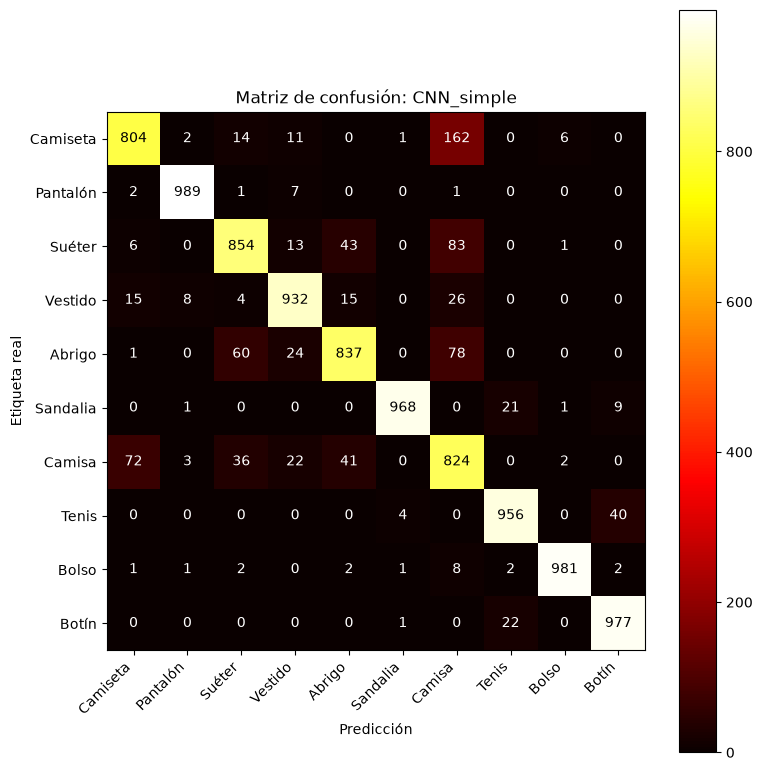

Accuracy test: 0.9122


In [12]:
from sklearn.metrics import confusion_matrix

best_for_plot = max(validation_accuracy, key=validation_accuracy.get)
best_test_predictions = np.argmax(models[best_for_plot].predict(X_test, verbose=0), axis=1)
test_cm = confusion_matrix(y_test, best_test_predictions)
fig, ax = plt.subplots(figsize=(8, 8))
image = ax.imshow(test_cm, cmap='hot')
fig.colorbar(image, ax=ax)
ax.set_xticks(range(len(CLASS_NAMES)), labels=CLASS_NAMES, rotation=45, ha='right')
ax.set_yticks(range(len(CLASS_NAMES)), labels=CLASS_NAMES)
ax.set_xlabel('Predicción')
ax.set_ylabel('Etiqueta real')
ax.set_title(f'Matriz de confusión: {best_for_plot}')
threshold = test_cm.max() / 2
for row in range(test_cm.shape[0]):
    for column in range(test_cm.shape[1]):
        ax.text(
            column, row, f'{test_cm[row, column]}',
            ha='center', va='center',
            color='white' if test_cm[row, column] < threshold else 'black',
        )
fig.tight_layout()
plt.show()
print(f"Accuracy test: {accuracy_score(y_test, best_test_predictions):.4f}")

## 4. Guardar el mejor modelo

In [5]:
best_name = max(validation_accuracy, key=validation_accuracy.get)
best_model = models[best_name]
best_model.save(PROJECT_DIR / 'best_fashion_cnn.keras')
(PROJECT_DIR / 'class_names.json').write_text(
    json.dumps(CLASS_NAMES, ensure_ascii=False, indent=2), encoding='utf-8'
)
print(f'Modelo seleccionado: {best_name}')
print(f"Accuracy de validación: {validation_accuracy[best_name]:.4f}")
print('Archivos guardados en:', PROJECT_DIR)

Modelo seleccionado: CNN_simple
Accuracy de validación: 0.9117
Archivos guardados en: c:\Users\Camus\OneDrive\Documentos\Projects\ai-projects\parcial3


## 5. Probar una imagen local (sin cámara)

Ejecuta la siguiente celda y selecciona una imagen JPG, JPEG o PNG desde tu computador. Se mostrará la imagen, la prenda predicha y su confianza. Esta opción funciona sin webcam.

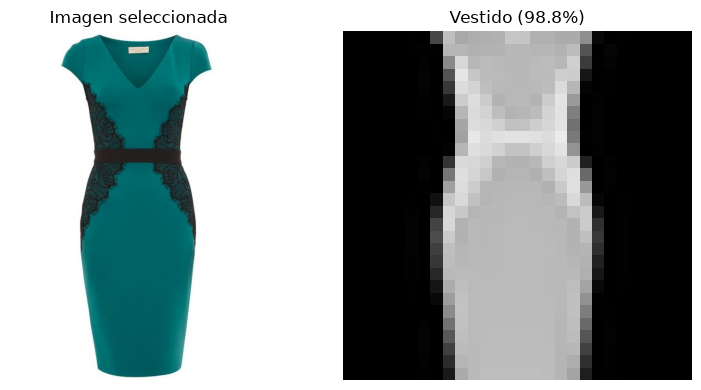

Predicción: Vestido | Confianza: 98.8%


In [16]:
from tkinter import Tk, filedialog
from PIL import Image, ImageOps

file_dialog = Tk()
file_dialog.withdraw()
file_dialog.attributes('-topmost', True)
image_path = filedialog.askopenfilename(
    title='Selecciona una imagen de una prenda',
    filetypes=[('Imágenes', '*.jpg *.jpeg *.png'), ('Todos los archivos', '*.*')],
)
file_dialog.destroy()

if image_path:
    original_image = Image.open(image_path).convert('RGB')
    gray_image = ImageOps.fit(
        original_image.convert('L'),
        (28, 28),
        method=Image.Resampling.LANCZOS,
    )
    image_pixels = np.asarray(gray_image, dtype=np.float32)
    border_pixels = np.concatenate((
        image_pixels[0, :], image_pixels[-1, :],
        image_pixels[:, 0], image_pixels[:, -1],
    ))
    if border_pixels.mean() > 127:
        image_pixels = 255.0 - image_pixels

    image_input = image_pixels.reshape(1, 28, 28, 1) / 255.0
    image_probabilities = best_model.predict(image_input, verbose=0)[0]
    predicted_class = int(np.argmax(image_probabilities))
    confidence = float(image_probabilities[predicted_class])

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(original_image)
    axes[0].set_title('Imagen seleccionada')
    axes[0].axis('off')
    axes[1].imshow(image_pixels, cmap='gray', vmin=0, vmax=255)
    axes[1].set_title(f'{CLASS_NAMES[predicted_class]} ({confidence:.1%})')
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()
    print(f'Predicción: {CLASS_NAMES[predicted_class]} | Confianza: {confidence:.1%}')
else:
    print('No se seleccionó ninguna imagen.')

## 6. Probar con cámara (opcional)

Si tienes webcam, ejecuta esta celda, presiona `espacio` para predecir y `q` para salir. Si no tienes cámara, omite la celda.

In [6]:
import cv2

camera = cv2.VideoCapture(0)
window_name = "Fashion-MNIST - espacio: capturar | q: salir"

if not camera.isOpened():
    print("No se pudo acceder a la cámara. Verifica permisos y conexión.")
else:
    print("Presiona espacio para predecir; presiona q para salir.")
    try:
        while True:
            success, frame = camera.read()
            if not success:
                print("No se pudo capturar imagen de la cámara.")
                break

            cv2.imshow(window_name, frame)
            key = cv2.waitKey(1) & 0xFF

            if key == ord("q"):
                break
            if key == ord(" "):
                gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
                image = cv2.resize(gray, (28, 28), interpolation=cv2.INTER_AREA)
                model_input = image.astype(np.float32).reshape(1, 28, 28, 1) / 255.0
                probabilities = best_model.predict(model_input, verbose=0)[0]
                predicted_class = int(np.argmax(probabilities))
                confidence = float(probabilities[predicted_class])
                prediction = f"{CLASS_NAMES[predicted_class]} ({confidence:.1%})"

                print(f"Predicción: {prediction}")
                cv2.putText(
                    frame, prediction, (10, 35), cv2.FONT_HERSHEY_SIMPLEX,
                    0.8, (0, 220, 80), 2, cv2.LINE_AA
                )
                cv2.imshow(window_name, frame)
                cv2.waitKey(900)
    finally:
        camera.release()
        cv2.destroyAllWindows()

No se pudo acceder a la cámara. Verifica permisos y conexión.
